# Mice protien EDA
dataset source: https://www.kaggle.com/datasets/uciml/mice-protein-expression


In [2]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples

# plot settings

sns.set_theme(style='whitegrid', palette='pastel', font_scale=1.2)

In [3]:
path = '../data/raw/mice_protein_expression.csv'

df_raw = pd.read_csv(path)

print(f"Shape of the dataset: {df_raw.shape}")
print(f"Columns of the dataset: {df_raw.columns.tolist()}")
df_raw.head()

Shape of the dataset: (1080, 81)
Columns of the dataset: ['DYRK1A_N', 'ITSN1_N', 'BDNF_N', 'NR1_N', 'NR2A_N', 'pAKT_N', 'pBRAF_N', 'pCAMKII_N', 'pCREB_N', 'pELK_N', 'pERK_N', 'pJNK_N', 'PKCA_N', 'pMEK_N', 'pNR1_N', 'pNR2A_N', 'pNR2B_N', 'pPKCAB_N', 'pRSK_N', 'AKT_N', 'BRAF_N', 'CAMKII_N', 'CREB_N', 'ELK_N', 'ERK_N', 'GSK3B_N', 'JNK_N', 'MEK_N', 'TRKA_N', 'RSK_N', 'APP_N', 'Bcatenin_N', 'SOD1_N', 'MTOR_N', 'P38_N', 'pMTOR_N', 'DSCR1_N', 'AMPKA_N', 'NR2B_N', 'pNUMB_N', 'RAPTOR_N', 'TIAM1_N', 'pP70S6_N', 'NUMB_N', 'P70S6_N', 'pGSK3B_N', 'pPKCG_N', 'CDK5_N', 'S6_N', 'ADARB1_N', 'AcetylH3K9_N', 'RRP1_N', 'BAX_N', 'ARC_N', 'ERBB4_N', 'nNOS_N', 'Tau_N', 'GFAP_N', 'GluR3_N', 'GluR4_N', 'IL1B_N', 'P3525_N', 'pCASP9_N', 'PSD95_N', 'SNCA_N', 'Ubiquitin_N', 'pGSK3B_Tyr216_N', 'SHH_N', 'BAD_N', 'BCL2_N', 'pS6_N', 'pCFOS_N', 'SYP_N', 'H3AcK18_N', 'EGR1_N', 'H3MeK4_N', 'CaNA_N', 'Genotype', 'Treatment', 'Behavior', 'class']


,DYRK1A_N,ITSN1_N,BDNF_N,NR1_N,NR2A_N,pAKT_N,pBRAF_N,pCAMKII_N,pCREB_N,pELK_N,...,pCFOS_N,SYP_N,H3AcK18_N,EGR1_N,H3MeK4_N,CaNA_N,Genotype,Treatment,Behavior,class
0,0.503644,0.747193,0.430175,2.816329,5.990152,0.218830,0.177565,2.373744,0.232224,1.750936,...,0.108336,0.427099,0.114783,0.131790,0.128186,1.675652,Control,Memantine,C/S,c-CS-m
1,0.514617,0.689064,0.411770,2.789514,5.685038,0.211636,0.172817,2.292150,0.226972,1.596377,...,0.104315,0.441581,0.111974,0.135103,0.131119,1.743610,Control,Memantine,C/S,c-CS-m
2,0.509183,0.730247,0.418309,2.687201,5.622059,0.209011,0.175722,2.283337,0.230247,1.561316,...,0.106219,0.435777,0.111883,0.133362,0.127431,1.926427,Control,Memantine,C/S,c-CS-m
3,0.442107,0.617076,0.358626,2.466947,4.979503,0.222886,0.176463,2.152301,0.207004,1.595086,...,0.111262,0.391691,0.130405,0.147444,0.146901,1.700563,Control,Memantine,C/S,c-CS-m
4,0.434940,0.617430,0.358802,2.365785,4.718679,0.213106,0.173627,2.134014,0.192158,1.504230,...,0.110694,0.434154,0.118481,0.140314,0.148380,1.839730,Control,Memantine,C/S,c-CS-m


In [4]:
# basic EDA before cleaning

print("\nColumn dtypes:")
print(df_raw.dtypes.value_counts())

print("\nMissing values (top 10 columns):")
print(df_raw.isnull().sum().sort_values(ascending=False).head(10))


Column dtypes:
float64    77
object      4
Name: count, dtype: int64

Missing values (top 10 columns):
BCL2_N        285
H3MeK4_N      270
BAD_N         213
EGR1_N        210
H3AcK18_N     180
pCFOS_N        75
ELK_N          18
Bcatenin_N     18
MEK_N           7
P38_N           3
dtype: int64


## Data cleaning

goals:
1. identify target variable
2. identify features and drop metadata columns (Genotype, Treatment, Behavior)
3. handle columns with missing values
4. convert protien columns to numeric values (Normalize the data)

In [5]:
df = df_raw.copy()

df.columns = df.columns.str.strip()  # remove leading/trailing whitespace from column names

target_col = df.columns[-1]  # assuming the last column is the target variable
print(f"\nTarget variable: {target_col}")
print(f"Unique values in target variable: {df[target_col].unique()}\n")


Target variable: class
Unique values in target variable: ['c-CS-m' 'c-SC-m' 'c-CS-s' 'c-SC-s' 't-CS-m' 't-SC-m' 't-CS-s' 't-SC-s']



In [6]:
# check missing values in target variable
missing_target = df[target_col].isnull().sum()
print(f"Missing values in target variable: {missing_target}")

Missing values in target variable: 0


No missing values in target variable.

In [7]:
metadata_cols = ['Genotype', 'Treatment', 'Behavior']

# drop metadata columns
if all(col in df.columns for col in metadata_cols):
    df.drop(columns=metadata_cols, inplace=True)

# check columns after dropping metadata
print(f"\nColumns after dropping metadata: {df.columns.tolist()}")

print("\nColumn dtypes after dropping metadata:")
print(df.dtypes.value_counts())


Columns after dropping metadata: ['DYRK1A_N', 'ITSN1_N', 'BDNF_N', 'NR1_N', 'NR2A_N', 'pAKT_N', 'pBRAF_N', 'pCAMKII_N', 'pCREB_N', 'pELK_N', 'pERK_N', 'pJNK_N', 'PKCA_N', 'pMEK_N', 'pNR1_N', 'pNR2A_N', 'pNR2B_N', 'pPKCAB_N', 'pRSK_N', 'AKT_N', 'BRAF_N', 'CAMKII_N', 'CREB_N', 'ELK_N', 'ERK_N', 'GSK3B_N', 'JNK_N', 'MEK_N', 'TRKA_N', 'RSK_N', 'APP_N', 'Bcatenin_N', 'SOD1_N', 'MTOR_N', 'P38_N', 'pMTOR_N', 'DSCR1_N', 'AMPKA_N', 'NR2B_N', 'pNUMB_N', 'RAPTOR_N', 'TIAM1_N', 'pP70S6_N', 'NUMB_N', 'P70S6_N', 'pGSK3B_N', 'pPKCG_N', 'CDK5_N', 'S6_N', 'ADARB1_N', 'AcetylH3K9_N', 'RRP1_N', 'BAX_N', 'ARC_N', 'ERBB4_N', 'nNOS_N', 'Tau_N', 'GFAP_N', 'GluR3_N', 'GluR4_N', 'IL1B_N', 'P3525_N', 'pCASP9_N', 'PSD95_N', 'SNCA_N', 'Ubiquitin_N', 'pGSK3B_Tyr216_N', 'SHH_N', 'BAD_N', 'BCL2_N', 'pS6_N', 'pCFOS_N', 'SYP_N', 'H3AcK18_N', 'EGR1_N', 'H3MeK4_N', 'CaNA_N', 'class']

Column dtypes after dropping metadata:
float64    77
object      1
Name: count, dtype: int64



Class distribution in target variable:
class
c-CS-m    150
c-CS-s    135
c-SC-m    150
c-SC-s    135
t-CS-m    135
t-CS-s    105
t-SC-m    135
t-SC-s    135
Name: count, dtype: int64


Text(0, 0.5, 'Count')

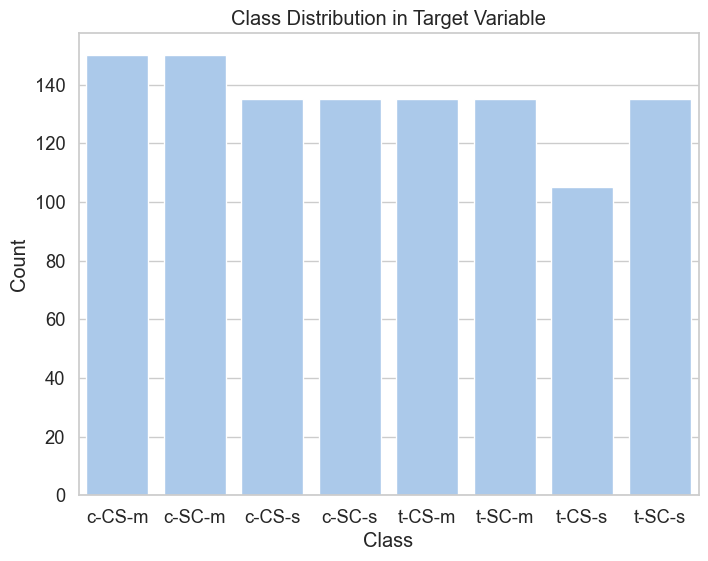

In [32]:
class_counts = df[target_col].value_counts().sort_index()
print(f"\nClass distribution in target variable:\n{class_counts}")

# class distribution plot
plt.figure(figsize=(8, 6))
sns.countplot(x=target_col, data=df)
plt.title('Class Distribution in Target Variable')
plt.xlabel('Class')
plt.ylabel('Count')

In [8]:
# convert protein columns to numeric values (Normalize the data)
protein_cols = df.columns[:-1]  # all columns except the target variable
df[protein_cols] = df[protein_cols].apply(pd.to_numeric, errors='coerce')

target_col = df.columns[-1]  # assuming the last column is the target variable

In [9]:
# Impute missing values in protein columns using median imputation
X = df[protein_cols].copy()
y_raw = df[target_col].astype(str).copy()

# Median imputation for missing values in protein columns
imputer = SimpleImputer(strategy='median')

X_imputed = pd.DataFrame(imputer.fit_transform(X), columns=protein_cols, index=X.index)
        
# check if there are any missing values in protein columns after imputation
missing_protein = X_imputed.isnull().sum().sum()
print(f"\nMissing values in protein columns after imputation: {missing_protein}")


Missing values in protein columns after imputation: 0


In [10]:
# Encode the target variable using LabelEncoder
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y_raw)

print(f"\nEncoded target variable classes: {label_encoder.classes_}")
print("label encoding mapping:")
for i, class_name in enumerate(label_encoder.classes_):
    print(f"  {class_name} -> {i}")


Encoded target variable classes: ['c-CS-m' 'c-CS-s' 'c-SC-m' 'c-SC-s' 't-CS-m' 't-CS-s' 't-SC-m' 't-SC-s']
label encoding mapping:
  c-CS-m -> 0
  c-CS-s -> 1
  c-SC-m -> 2
  c-SC-s -> 3
  t-CS-m -> 4
  t-CS-s -> 5
  t-SC-m -> 6
  t-SC-s -> 7


In [11]:
# Data normalization (Standardization) of protein columns
scaler = StandardScaler()
X_normalized = scaler.fit_transform(X_imputed)

X_normalized_df = pd.DataFrame(X_normalized, columns=protein_cols, index=X_imputed.index)

print("Scaled feature matrix shape:", X_normalized_df.shape)
X_normalized_df.head()

Scaled feature matrix shape: (1080, 77)


,DYRK1A_N,ITSN1_N,BDNF_N,NR1_N,NR2A_N,pAKT_N,pBRAF_N,pCAMKII_N,pCREB_N,pELK_N,...,SHH_N,BAD_N,BCL2_N,pS6_N,pCFOS_N,SYP_N,H3AcK18_N,EGR1_N,H3MeK4_N,CaNA_N
0,0.313350,0.518471,2.253803,1.497368,2.304588,-0.344885,-0.158648,-0.899416,0.604281,0.691885,...,-1.305403,-1.286899,-0.164944,-1.066276,-0.972480,-0.285744,-0.973682,-1.367167,-1.540161,1.065901
1,0.357433,0.287052,1.880415,1.420015,1.976995,-0.517992,-0.334569,-0.962530,0.442825,0.360253,...,-0.906725,-1.511815,-0.164944,-1.046167,-1.147005,-0.067645,-1.025367,-1.276125,-1.479437,1.280291
2,0.335603,0.451006,2.013063,1.124866,1.909375,-0.581163,-0.226938,-0.969347,0.543502,0.285024,...,-1.138611,-1.443018,-0.164944,-0.926271,-1.064360,-0.155059,-1.027034,-1.323973,-1.555782,1.857038
3,0.066132,0.000465,0.802262,0.489487,1.219480,-0.247290,-0.199508,-1.070704,-0.171066,0.357483,...,-1.192887,-0.905279,-0.164944,-1.285019,-0.845461,-0.818989,-0.686310,-0.936981,-1.152691,1.144490
4,0.037342,0.001873,0.805831,0.197657,0.939439,-0.482624,-0.304563,-1.084849,-0.627499,0.162535,...,-0.727242,-1.011791,-0.164944,-1.172895,-0.870119,-0.179502,-0.905652,-1.132915,-1.122074,1.583530


### PCA

PC1 explained variance ratio: 0.2535
PC2 explained variance ratio: 0.1691
Total explained variance: 0.4226


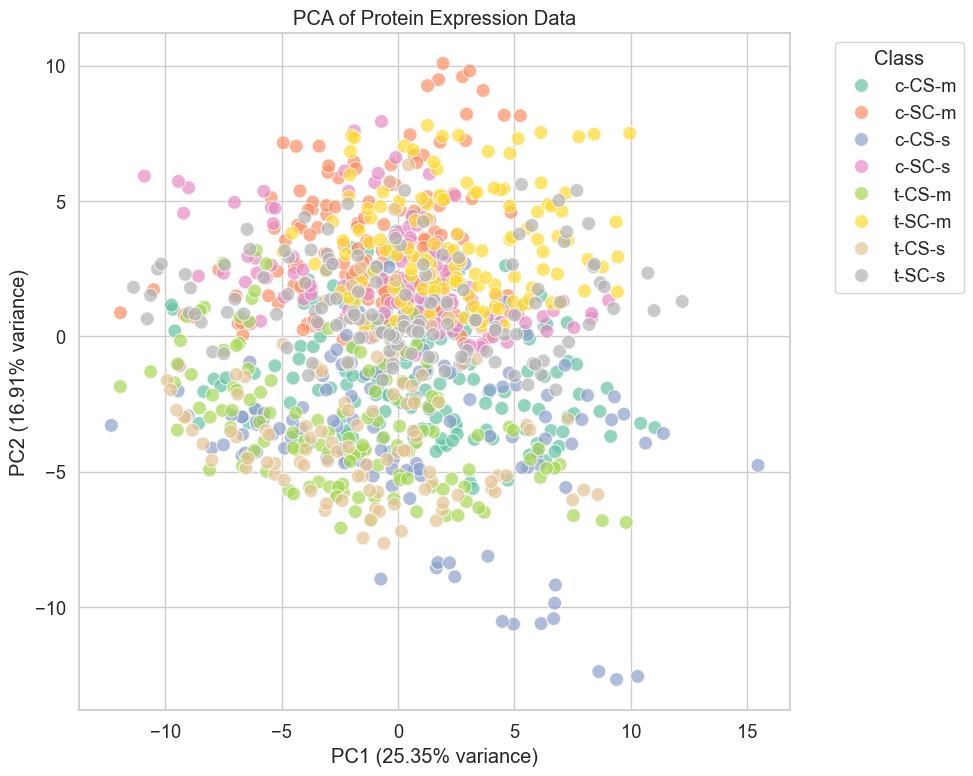

In [17]:
pca = PCA(n_components=2, random_state=42)

X_pca = pca.fit_transform(X_normalized_df)

X_pca_df = pd.DataFrame(X_pca, columns=['PC1', 'PC2'], index=X_normalized_df.index)
X_pca_df["class"] = y_raw.values

evr = pca.explained_variance_ratio_

print(f"PC1 explained variance ratio: {evr[0]:.4f}")
print(f"PC2 explained variance ratio: {evr[1]:.4f}")
print(f"Total explained variance: {evr.sum():.4f}")

plt.figure(figsize=(10, 8))
sns.scatterplot(x='PC1', y='PC2', hue='class', data=X_pca_df, palette='Set2', s=100, alpha=0.7)
plt.title('PCA of Protein Expression Data')
plt.xlabel(f'PC1 ({evr[0]*100:.2f}% variance)')
plt.ylabel(f'PC2 ({evr[1]*100:.2f}% variance)')
plt.legend(title='Class', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

### K-Means

In [42]:
K = 8 # class count
kmeans = KMeans(n_clusters=K, random_state=42)

cluster_labels = kmeans.fit_predict(X_normalized_df)
X_pca_df["cluster"] = cluster_labels.astype(str)

# silhouette score
silhouette_avg = silhouette_score(X_normalized_df, cluster_labels)
silhouette_samples_values = silhouette_samples(X_normalized_df, cluster_labels)

print(f"\nSilhouette Score for K={K}: {silhouette_avg:.4f}")
print(f"Intertia (Sum of squared distances to closest cluster center): {kmeans.inertia_:.4f}")

print(f"\nCluster sizes:")
print(pd.Series(cluster_labels).value_counts().sort_index())


Silhouette Score for K=8: 0.1225
Intertia (Sum of squared distances to closest cluster center): 48173.4558

Cluster sizes:
0    145
1    222
2    160
3    168
4    165
5    117
6     15
7     88
Name: count, dtype: int64


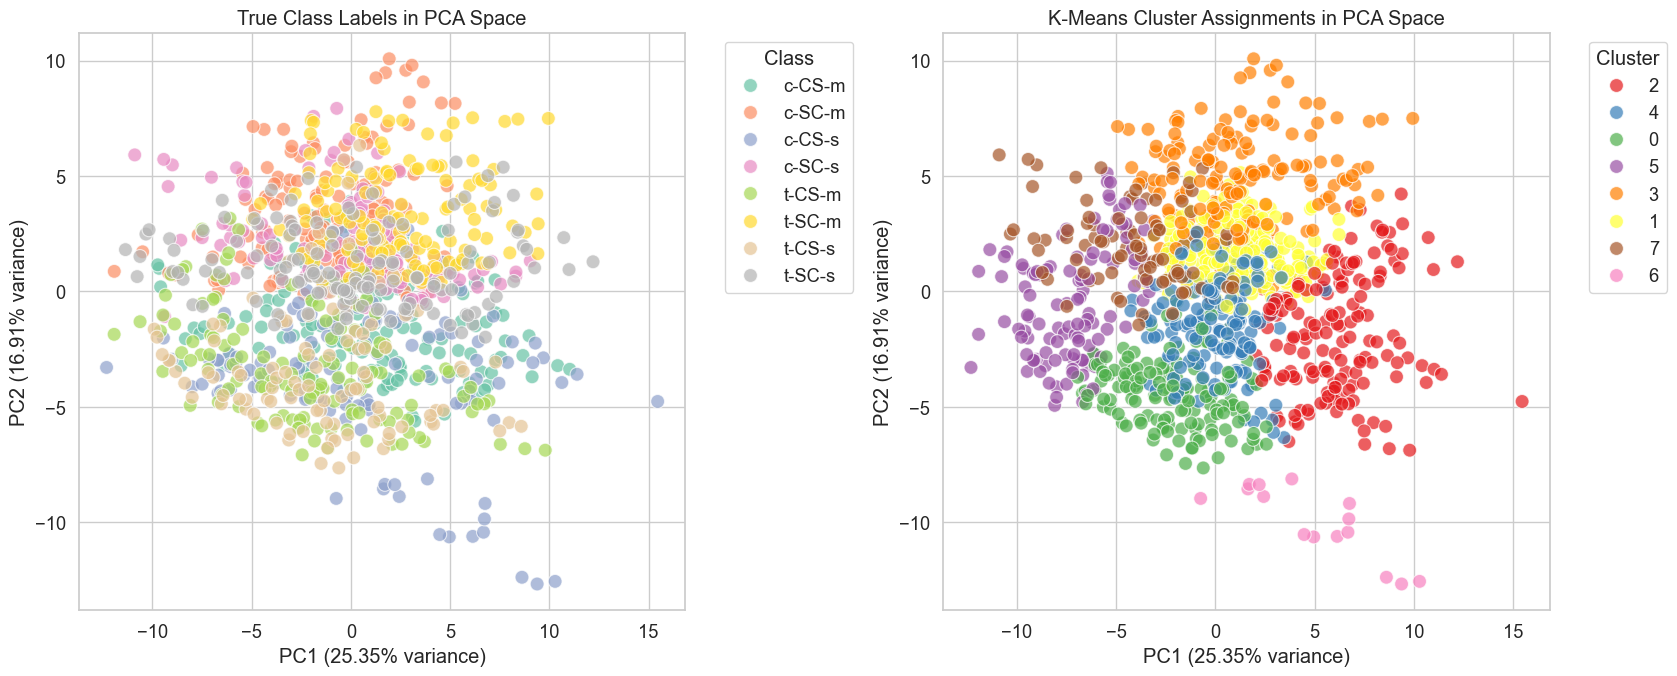

In [44]:
# Comparison of true class labels and K-Means cluster assignments in PCA space

fig,ax = plt.subplots(1,2,figsize=(17, 7))
sns.scatterplot(x='PC1', y='PC2', hue='class', data=X_pca_df, palette='Set2', s=100, alpha=0.7, ax=ax[0])
ax[0].set_title('True Class Labels in PCA Space')
ax[0].set_xlabel(f'PC1 ({evr[0]*100:.2f}% variance)')
ax[0].set_ylabel(f'PC2 ({evr[1]*100:.2f}% variance)')
ax[0].legend(title='Class', bbox_to_anchor=(1.05, 1), loc='upper left')

sns.scatterplot(x='PC1', y='PC2', hue='cluster', data=X_pca_df, palette='Set1', s=100, alpha=0.7, ax=ax[1])
ax[1].set_title('K-Means Cluster Assignments in PCA Space')
ax[1].set_xlabel(f'PC1 ({evr[0]*100:.2f}% variance)')
ax[1].set_ylabel(f'PC2 ({evr[1]*100:.2f}% variance)')
ax[1].legend(title='Cluster', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [46]:
# Clustering evaluation metrics

silhouette_summary = pd.DataFrame({
    "class": y_raw.values,
    'Cluster': cluster_labels.astype(str),
    "Silhouette": silhouette_samples_values
})

print("average silhouette score by true class:")
print(silhouette_summary.groupby("class")["Silhouette"].mean().sort_values(ascending=False))

print("\naverage silhouette score by cluster:")
print(silhouette_summary.groupby("Cluster")["Silhouette"].mean().sort_values(ascending=False))

print("\nCross-tabulation of true class labels and K-Means cluster assignments:")
print(pd.crosstab(silhouette_summary["class"], silhouette_summary["Cluster"]))

average silhouette score by true class:
class
c-CS-s    0.162495
c-SC-m    0.139683
t-CS-m    0.139067
c-SC-s    0.135301
t-SC-m    0.108631
t-CS-s    0.108083
c-CS-m    0.096067
t-SC-s    0.088716
Name: Silhouette, dtype: float64

average silhouette score by cluster:
Cluster
6    0.488034
1    0.210418
4    0.124708
5    0.121659
7    0.119772
2    0.119463
0    0.105563
3   -0.008783
Name: Silhouette, dtype: float64

Cross-tabulation of true class labels and K-Means cluster assignments:
Cluster   0   1   2   3   4   5   6   7
class                                  
c-CS-m   16  10  54  19  34  17   0   0
c-CS-s   42   0  25   6  35  12  15   0
c-SC-m    0  77   0  43   0  20   0  10
c-SC-s    0  71  12  22   0  10   0  20
t-CS-m   37   0  13   0  49  36   0   0
t-CS-s   48   0  13   7  23  12   0   2
t-SC-m    0  59  12  51   0   3   0  10
t-SC-s    2   5  31  20  24   7   0  46


From the cross-tabulation, unsupervised clustering (K-Means) revels that the dominant protien expression pattern are driven by behavoiur (CS, SC) and Genotype (c, t). The pharmacological treatment (saline, cocaine) is too subtle to be captured by K-Means as a primary group factor.